# 1 — Preparação do ambiente
Ativar a GPU em:

Ambiente de execução → Alterar tipo de ambiente de execução → T4 GPU (se disponível).

Importar as bibliotecas:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay

print("TensorFlow:", tf.__version__)
print("GPU disponível:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU disponível: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# 2 — Carregamento da base CIFAR-10
O próprio TensorFlow disponibiliza a base, não sendo necessário baixar arquivos manualmente.

In [2]:
# Carregamento da base CIFAR-10
(x_treino, y_treino), (x_teste, y_teste) = (
    tf.keras.datasets.cifar10.load_data()
)

# Conversão dos rótulos para vetor
y_treino = y_treino.flatten()
y_teste = y_teste.flatten()

print("Imagens de treinamento:", x_treino.shape)
print("Rótulos de treinamento:", y_treino.shape)

print("Imagens de teste:", x_teste.shape)
print("Rótulos de teste:", y_teste.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2442s 14us/step
Imagens de treinamento: (50000, 32, 32, 3)
Rótulos de treinamento: (50000,)
Imagens de teste: (10000, 32, 32, 3)
Rótulos de teste: (10000,)


#3 — Visualização das imagens
Antes de treinar a rede, vamos observar algumas imagens da base e suas respectivas classes.

Essa visualização permite identificar a diversidade das imagens e compreender o desafio da classificação.

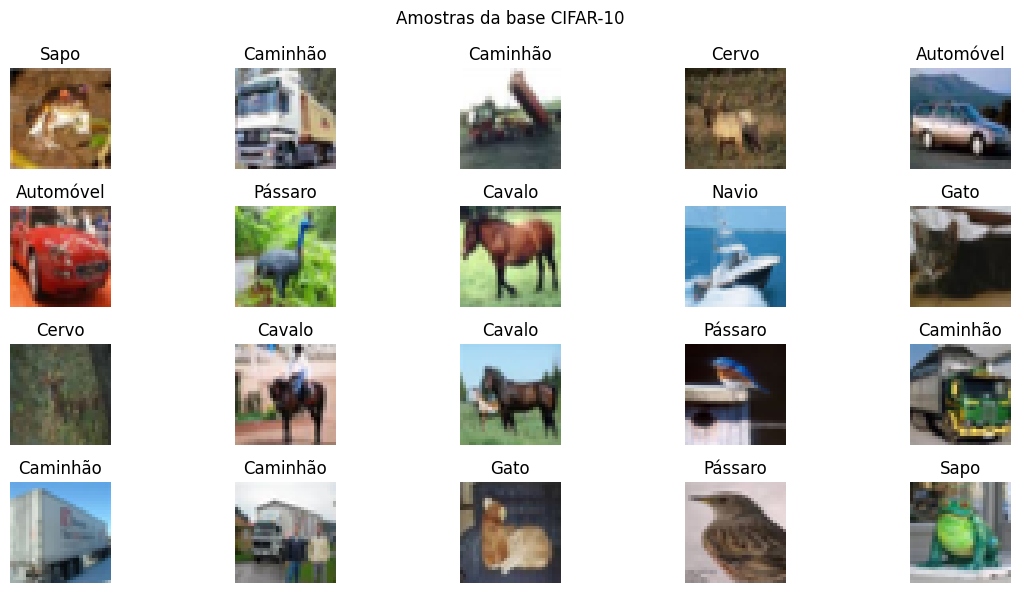

In [3]:
classes = [
    'Avião',
    'Automóvel',
    'Pássaro',
    'Gato',
    'Cervo',
    'Cachorro',
    'Sapo',
    'Cavalo',
    'Navio',
    'Caminhão'
]

plt.figure(figsize=(12, 6))

for i in range(20):
    plt.subplot(4, 5, i + 1)

    plt.imshow(x_treino[i])
    plt.title(classes[y_treino[i]])
    plt.axis('off')

plt.suptitle('Amostras da base CIFAR-10')
plt.tight_layout()
plt.show()

# 4 — Separação dos dados de validação
A base já possui uma divisão oficial entre treinamento e teste.

Vamos retirar 5.000 imagens do conjunto de treinamento para utilizar na validação.

Treinamento	45.000

Validação	5.000

Teste	10.000

In [4]:
from sklearn.model_selection import train_test_split

x_treino, x_validacao, y_treino, y_validacao = train_test_split(
    x_treino,
    y_treino,
    test_size=0.10,
    random_state=42,
    stratify=y_treino
)

print("Treinamento:", x_treino.shape)
print("Validação:", x_validacao.shape)
print("Teste:", x_teste.shape)

Treinamento: (45000, 32, 32, 3)
Validação: (5000, 32, 32, 3)
Teste: (10000, 32, 32, 3)


# 5 — Verificação e preparação das imagens

In [5]:
# Verificando as dimensões das imagens
print("Dimensões das imagens:", x_treino.shape[1:])
print("Valor mínimo dos pixels:", x_treino.min())
print("Valor máximo dos pixels:", x_treino.max())

# Verificando a quantidade de classes
print("Classes existentes:", np.unique(y_treino))

# Verificando se existem valores ausentes
print("Valores ausentes:", np.isnan(x_treino).sum())

Dimensões das imagens: (32, 32, 3)
Valor mínimo dos pixels: 0
Valor máximo dos pixels: 255
Classes existentes: [0 1 2 3 4 5 6 7 8 9]
Valores ausentes: 0


#6 — Data Augmentation
Vamos utilizar algumas transformações nas imagens de treinamento:
- Inversão horizontal.
- Pequenas rotações.
- Pequenas alterações de zoom.
Isso aumenta a diversidade dos exemplos apresentados à rede e pode ajudar a reduzir o sobreajuste.

In [6]:
aumento_dados = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10)
], name="aumento_dados")

#7 — Carregamento da CNN pré-treinada
Agora vamos carregar a MobileNetV2 com os pesos do ImageNet.

In [7]:
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

# Congelamento das camadas pré-treinadas
base_model.trainable = False

print("MobileNetV2 carregada!")
print("Quantidade de camadas:", len(base_model.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 carregada!
Quantidade de camadas: 154


# 8 — Construção da arquitetura com Transfer Learning
Agora vamos adicionar novas camadas responsáveis pela classificação das dez categorias do CIFAR-10.

In [8]:
entradas = layers.Input(shape=(32, 32, 3))

# Aumento de dados
x = aumento_dados(entradas)

# Redimensionamento das imagens
x = layers.Resizing(96, 96)(x)

# Pré-processamento da MobileNetV2
x = layers.Lambda(
    tf.keras.applications.mobilenet_v2.preprocess_input
)(x)

# Extração de características
x = base_model(x, training=False)

# Classificador personalizado
x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.30)(x)

saidas = layers.Dense(
    10,
    activation='softmax'
)(x)

# Modelo completo
modelo = models.Model(
    inputs=entradas,
    outputs=saidas
)

modelo.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento_dados (Sequential)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

# 9 — Compilação e treinamento inicial
Vamos utilizar:
- Otimizador Adam.
- Função de custo Sparse Categorical Crossentropy.
- Métrica de acurácia.
- 15 épocas inicialmente.

In [9]:
modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

parada = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

historico_inicial = modelo.fit(
    x_treino,
    y_treino,
    validation_data=(x_validacao, y_validacao),
    epochs=15,
    batch_size=64,
    callbacks=[parada]
)

Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 28s 28ms/step - accuracy: 0.6062 - loss: 1.1676 - val_accuracy: 0.8100 - val_loss: 0.5773
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 25ms/step - accuracy: 0.6832 - loss: 0.9167 - val_accuracy: 0.8216 - val_loss: 0.5225
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 26ms/step - accuracy: 0.6957 - loss: 0.8810 - val_accuracy: 0.8278 - val_loss: 0.5148
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 25ms/step - accuracy: 0.6997 - loss: 0.8728 - val_accuracy: 0.8186 - val_loss: 0.5380
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6966 - loss: 0.8737 - val_accuracy: 0.8278 - val_loss: 0.5177
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.6957 - loss: 0.8758 - val_accuracy: 0.8312 - val_loss: 0.4992
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.7004 - loss: 0.8686 - val_accuracy: 0.8360 - val_loss: 0.4915
Epoch 8/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 26ms/step - accuracy: 0.7032 - loss: 0.8660 - 

# 10 — Fine-tuning da rede
Agora vamos realizar uma etapa adicional de Transfer Learning chamada Fine-tuning.

Nessa etapa, vamos liberar as últimas 30 camadas da MobileNetV2 para que elas também possam aprender características específicas das imagens CIFAR-10.

In [10]:
# Libera a rede pré-treinada
base_model.trainable = True

# Congela todas, exceto as últimas 30 camadas
for camada in base_model.layers[:-30]:
    camada.trainable = False

# Mantém as camadas BatchNormalization congeladas
for camada in base_model.layers:
    if isinstance(camada, layers.BatchNormalization):
        camada.trainable = False

# Recompila com taxa de aprendizado menor
modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

historico_finetuning = modelo.fit(
    x_treino,
    y_treino,
    validation_data=(x_validacao, y_validacao),
    epochs=8,
    batch_size=64,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=3,
            restore_best_weights=True
        )
    ]
)

Epoch 1/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 34s 41ms/step - accuracy: 0.7249 - loss: 0.7907 - val_accuracy: 0.8430 - val_loss: 0.4690
Epoch 2/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 27s 39ms/step - accuracy: 0.7471 - loss: 0.7170 - val_accuracy: 0.8478 - val_loss: 0.4441
Epoch 3/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 27s 38ms/step - accuracy: 0.7641 - loss: 0.6799 - val_accuracy: 0.8614 - val_loss: 0.4139
Epoch 4/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 27s 38ms/step - accuracy: 0.7758 - loss: 0.6432 - val_accuracy: 0.8588 - val_loss: 0.4161
Epoch 5/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 27s 38ms/step - accuracy: 0.7847 - loss: 0.6200 - val_accuracy: 0.8636 - val_loss: 0.4021
Epoch 6/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 27s 38ms/step - accuracy: 0.7937 - loss: 0.5924 - val_accuracy: 0.8764 - val_loss: 0.3738
Epoch 7/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 28s 39ms/step - accuracy: 0.7974 - loss: 0.5795 - val_accuracy: 0.8794 - val_loss: 0.3599
Epoch 8/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 27s 39ms/step - accuracy: 0.8056 - loss: 0.5585 - val_accu

#11 — Visualização das curvas de treinamento
Vamos juntar os históricos das duas etapas para observar a evolução do aprendizado.

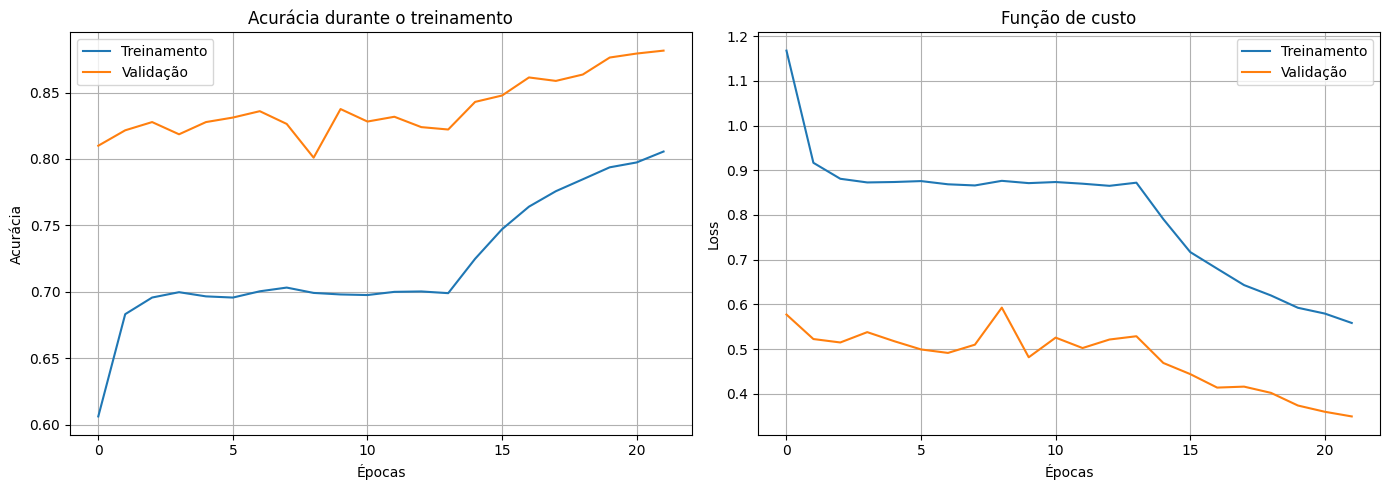

In [11]:
# Histórico combinado
acuracia_treino = (
    historico_inicial.history['accuracy'] +
    historico_finetuning.history['accuracy']
)

acuracia_validacao = (
    historico_inicial.history['val_accuracy'] +
    historico_finetuning.history['val_accuracy']
)

perda_treino = (
    historico_inicial.history['loss'] +
    historico_finetuning.history['loss']
)

perda_validacao = (
    historico_inicial.history['val_loss'] +
    historico_finetuning.history['val_loss']
)

# Gráficos
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(acuracia_treino, label='Treinamento')
ax[0].plot(acuracia_validacao, label='Validação')
ax[0].set_title('Acurácia durante o treinamento')
ax[0].set_xlabel('Épocas')
ax[0].set_ylabel('Acurácia')
ax[0].legend()
ax[0].grid()

ax[1].plot(perda_treino, label='Treinamento')
ax[1].plot(perda_validacao, label='Validação')
ax[1].set_title('Função de custo')
ax[1].set_xlabel('Épocas')
ax[1].set_ylabel('Loss')
ax[1].legend()
ax[1].grid()

plt.tight_layout()
plt.show()

# 12 — Avaliação com o conjunto de teste
Agora vamos utilizar as 10.000 imagens que ficaram completamente separadas do treinamento e da validação.

In [12]:
# Avaliação do modelo
resultado = modelo.evaluate(
    x_teste,
    y_teste,
    batch_size=64,
    verbose=1
)

print("Loss no teste:", resultado[0])
print("Acurácia no teste:", resultado[1] * 100, "%")

157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.8756 - loss: 0.3635
Loss no teste: 0.36351656913757324
Acurácia no teste: 87.55999803543091 %


# 13 — Geração das previsões
Vamos obter a classe prevista para cada imagem do conjunto de teste.

In [13]:
# Probabilidades previstas
previsoes = modelo.predict(
    x_teste,
    batch_size=64
)

# Classe com maior probabilidade
y_pred = np.argmax(previsoes, axis=1)

print("Previsões concluídas!")
print("Total de imagens classificadas:", len(y_pred))

157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step
Previsões concluídas!
Total de imagens classificadas: 10000


# 14 — Matriz de confusão
Esta é a principal entrega solicitada pelo enunciado.

A matriz de confusão apresenta as classificações realizadas pela rede neural, permitindo identificar os acertos e os erros entre as dez categorias.

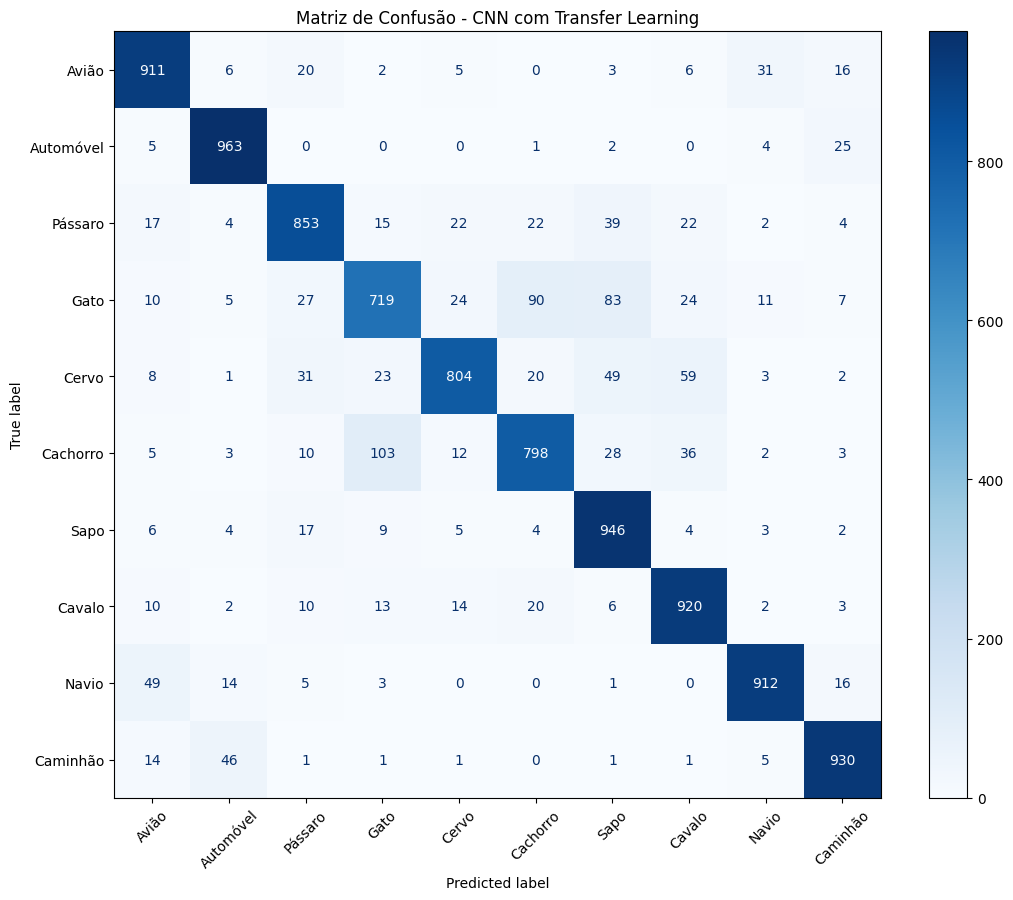

In [14]:
# Construção da matriz de confusão
matriz = confusion_matrix(
    y_teste,
    y_pred
)

# Exibição
fig, ax = plt.subplots(figsize=(11, 9))

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=classes
)

disp.plot(
    cmap='Blues',
    values_format='d',
    ax=ax,
    xticks_rotation=45
)

plt.title('Matriz de Confusão - CNN com Transfer Learning')
plt.tight_layout()
plt.show()

# 15 — Métricas complementares
Embora o enunciado solicite especificamente a matriz de confusão, podemos apresentar também outras métricas para enriquecer a análise.

In [15]:
print(classification_report(
    y_teste,
    y_pred,
    target_names=classes,
    digits=4
))

              precision    recall  f1-score   support

       Avião     0.8802    0.9110    0.8953      1000
   Automóvel     0.9189    0.9630    0.9404      1000
     Pássaro     0.8758    0.8530    0.8642      1000
        Gato     0.8097    0.7190    0.7617      1000
       Cervo     0.9064    0.8040    0.8521      1000
    Cachorro     0.8356    0.7980    0.8164      1000
        Sapo     0.8169    0.9460    0.8767      1000
      Cavalo     0.8582    0.9200    0.8880      1000
       Navio     0.9354    0.9120    0.9235      1000
    Caminhão     0.9226    0.9300    0.9263      1000

    accuracy                         0.8756     10000
   macro avg     0.8760    0.8756    0.8745     10000
weighted avg     0.8760    0.8756    0.8745     10000



# 16 — Visualização das previsões
Para finalizar, vamos apresentar algumas imagens do conjunto de teste com as respectivas classificações realizadas pela rede.

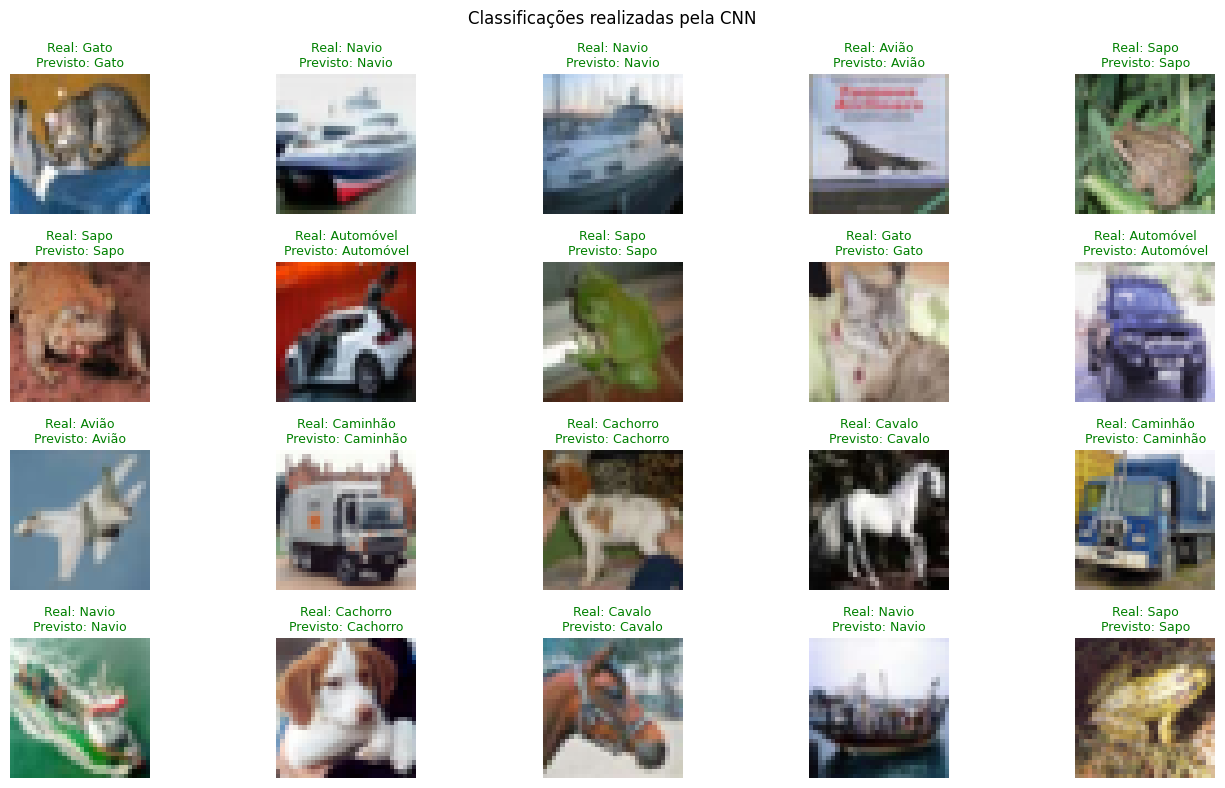

In [16]:
plt.figure(figsize=(14, 8))

for i in range(20):
    plt.subplot(4, 5, i + 1)

    plt.imshow(x_teste[i])

    real = classes[y_teste[i]]
    previsto = classes[y_pred[i]]

    cor = 'green' if y_teste[i] == y_pred[i] else 'red'

    plt.title(
        f'Real: {real}\nPrevisto: {previsto}',
        color=cor,
        fontsize=9
    )

    plt.axis('off')

plt.suptitle('Classificações realizadas pela CNN')
plt.tight_layout()
plt.show()

## Conclusão

Neste experimento foi desenvolvida uma Rede Neural Convolucional (CNN) utilizando a técnica de Transfer Learning para realizar a classificação de imagens da base de dados CIFAR-10.

Foi utilizada a arquitetura MobileNetV2, previamente treinada na base ImageNet, aproveitando suas características convolucionais já aprendidas para adaptar o modelo à classificação de dez categorias de imagens.

Inicialmente, as camadas convolucionais pré-treinadas foram mantidas congeladas, enquanto novas camadas de classificação foram adicionadas e treinadas para reconhecer as categorias do CIFAR-10. Posteriormente, foi realizada uma etapa de Fine-tuning, permitindo o ajuste das últimas camadas da rede para melhorar sua adaptação ao problema proposto.

A avaliação foi realizada utilizando o conjunto de teste, composto por 10.000 imagens que não participaram do treinamento. Os resultados foram apresentados por meio de uma matriz de confusão, possibilitando identificar os acertos e erros da classificação para cada uma das dez categorias.

Dessa forma, o experimento demonstra a aplicação de Transfer Learning em problemas de visão computacional, evidenciando como uma rede convolucional previamente treinada pode ser adaptada para uma nova tarefa de classificação de imagens.